# CSC_51054_EP - Deep Learning
## Lab 6 - Transformer and Transfer Learning

In [1]:
import math
import random
import time
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sentencepiece as spm  # tokenizer; if this import fails, run: pip install sentencepiece
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import HTML, display
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

device: mps


### 1. Introduction:
<p style="text-align: justify;">
Transfer learning, that is, solving tasks with models that have been pretrained on very large amounts of data, was a game changer in many deep learning tasks. In NLP, while annotated data are scarce, raw text is virtually unlimited and readily available. Thus, the ability to learn good representations from plain text could greatly improve general natural language understanding. Learning without labels is enabled via self-supervised learning, a setting in which a system learns to predict part of its input from other parts of its input.

<p>One way to realise this pre-training is to use <i>generative pre-training</i> <a href="https://www.cs.ubc.ca/~amuham01/LING530/papers/radford2018improving.pdf" target='_blank'>[1]</a> of a language model. In this pre-training phase, the model will learn to predict the next tokens in a sequence given the previous ones.</p>
<p>Thus, this phase does not require any type of annotations apart from the input text itself. Once the language model is sufficiently pre-trained, it can be fine-tuned on supervised tasks while requiring minimal changes to its architecture (replacing the classification head).</p>

Our model is based on Transformers <a href="https://arxiv.org/abs/1706.03762" target='_blank'>[2]</a>. In this lab we will:
<ul>
    <li>Implement the attention mechanism and a Transformer block from scratch, and check them against PyTorch's own implementation.</li>
    <li>Implement and pretrain a language model with transformer architecture.</li>
    <li>Load a pretrained checkpoint into our own implementation, generate text, and visualize what the attention heads look at.</li>
    <li>Use the pretrained model (transfer learning) to perform a sentiment analysis task which consists of classifying some books reviews into positive and negative ones.</li>
    <li>Compare the performance of the pretrained model to a model trained from scratch.</li>
</ul>

By the end, you should be able to:

- compute scaled dot-product attention, and explain the role of the scaling and of the causal mask;
- implement multi-head self-attention and a Transformer block, and follow the tensor shapes at each step;
- explain why a pretrained model fine-tunes faster and better than a model trained from scratch;
- read attention maps, and say what they can and cannot tell us.

**Data.** All the files used in this lab (vocabulary, tokenizer, datasets, and a pretrained checkpoint; about 100 MB in total) are in the folder `lab6_data`, supplied with this notebook. The notebook reads them from this folder and does not download anything. Keep the folder name and the 8 file names as they are.

**If you are running the notebook locally:** keep the folder `lab6_data` in the same folder as the notebook, then run the next cell. It prints the folder it is checking and checks that the 8 files are present. Python cannot reliably discover an open notebook's location in every Jupyter environment, so the cell uses the kernel's current working directory. If the printed folder is not the folder containing the notebook and `lab6_data`, change only the `NOTEBOOK_FOLDER` line and rerun the cell. The required packages are listed in `requirements.txt`; install them with `pip install -r requirements.txt`.

**If you are using Google Colab in your browser:** first open the notebook in Colab. Click the folder icon in the left sidebar, choose **Upload to session storage**, and select the 8 files inside `lab6_data` (you can select them all at once). Wait until they all appear in the file list (the checkpoint `pretrained_model_4layers.pt` is about 90 MB), then run the next cell: it also looks for the files directly next to the notebook. All the required packages are already installed on Colab. Colab session storage is temporary, so after a runtime reset or disconnection you will need to upload the files again.

**Running time.** On a recent laptop, the whole notebook runs in about 10 minutes; on a GPU it is faster.

In [2]:
DATA_FILES = [
    "dict.txt",
    "sentencepiece.french.model",
    "pretraining_subset.txt",
    "pretrained_model_4layers.pt",
    "train.review.spm",
    "train.label",
    "test.review.spm",
    "test.label",
]

NOTEBOOK_FOLDER = Path.cwd().resolve()
DATA_DIR = NOTEBOOK_FOLDER / "lab6_data"
if not DATA_DIR.is_dir():
    # on Google Colab, the files are uploaded directly next to the notebook
    DATA_DIR = NOTEBOOK_FOLDER

print("Folder used for this notebook:", NOTEBOOK_FOLDER)
print("Data folder:                  ", DATA_DIR)

missing = [name for name in DATA_FILES if not (DATA_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(
        f"These data files were not found in {DATA_DIR}:\n  " + "\n  ".join(missing) + "\n"
        "Local: keep the folder lab6_data, with its 8 files, beside the notebook.\n"
        "Google Colab: upload the 8 files of lab6_data using the Files panel in the left sidebar.\n"
        "If a local notebook uses a different folder, change NOTEBOOK_FOLDER in this cell."
    )

print("All the data files were found.")

Folder used for this notebook: /Users/user/Documents/3A/P1/CSC_DL/Lab6_student
Data folder:                   /Users/user/Documents/3A/P1/CSC_DL/Lab6_student/lab6_data
All the data files were found.


## 2. Attention from Scratch

The key ingredient of a Transformer is the **attention** mechanism. Before using PyTorch's ready-made layers, we implement it ourselves, and we check at each step that we get exactly the same numbers as PyTorch.

### 2.1 Scaled dot-product attention

`Each token of a sequence is represented by a vector.` Attention lets every token build a new representation by **looking at the other tokens** and taking a weighted average of what they contain. For this, each token $i$ is given three vectors:

- a **query** $q_i$: what token $i$ is looking for;
- a **key** $k_j$: what token $j$ offers, to be compared with the queries;
- a **value** $v_j$: the information that token $j$ passes on.

Stacking these vectors as rows gives three matrices $Q\in\mathbb{R}^{T\times d_k}$, $K\in\mathbb{R}^{T\times d_k}$ and $V\in\mathbb{R}^{T\times d_v}$ for a sequence of $T$ tokens, and

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V .
$$

Step by step:

1. **scores** $S=QK^\top/\sqrt{d_k}$, of shape $T\times T$: $S_{ij}$ measures how well query $i$ matches key $j$;
2. **attention weights** $A=\operatorname{softmax}(S)$, where the softmax is applied to each row: row $i$ is a probability distribution over the tokens $j$ (non-negative, sums to 1);
3. **output** $AV$: row $i$ is the average of the values, weighted by row $i$ of $A$.

In practice the tensors have extra leading dimensions, for example `(B, h, T, d_k)` for a batch of `B` sequences and `h` heads (Section 2.4). The operator `@` and `.transpose(-2, -1)` act on the last two dimensions only and treat the other ones as batch dimensions, so the same code works for any number of leading dimensions.

The function also takes an optional boolean `mask`, which is `True` where attention is allowed. Where it is `False`, the score is replaced by $-\infty$, so that the softmax gives a weight of exactly 0. We will use it in Section 2.3.

---

**Task 1**: In the function `scaled_dot_product_attention` (next cell), complete the four lines `scores = ...`, `scores = ...` (masking), `weights = ...` and `output = ...`, following the three steps above. For the masking, `tensor.masked_fill(condition, value)` replaces the entries where `condition` is `True` by `value`, and `~mask` is the opposite of `mask`.

In [3]:
def scaled_dot_product_attention(q, k, v, mask=None):
    """
    Computes softmax(q k^T / sqrt(d_k)) v
    input:
        q (torch.Tensor): (..., T_q, d_k) queries
        k (torch.Tensor): (..., T_k, d_k) keys
        v (torch.Tensor): (..., T_k, d_v) values
        mask (torch.Tensor or None): (T_q, T_k) booleans, True where attention is allowed

    returns:
        output (torch.Tensor): (..., T_q, d_v)
        weights (torch.Tensor): (..., T_q, T_k) attention weights, each row sums to 1
    """
    d_k = q.shape[-1]
    scores = q@k.transpose(-2,-1) / (np.sqrt(d_k)) #> YOUR CODE HERE: the scores q k^T / sqrt(d_k), of shape (..., T_q, T_k) 
    # we want to transpose only the last 2 of the tensor!!!
    if mask is not None:
        scores = scores.masked_fill(~mask, -torch.inf)  #> YOUR CODE HERE: -inf where the mask is False
    weights = torch.softmax(scores, dim= -1)  #> YOUR CODE HERE: softmax over the keys (the last dimension)
    output = weights @ v  #> YOUR CODE HERE: weighted average of the values
    return output, weights

Let's try it on a toy sequence of three tokens with $d_k=d_v=2$:

$$
Q=K=\begin{bmatrix}1&0\\0&2\\1&1\end{bmatrix},\qquad
V=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}.
$$

For the first token, the scores are $q_1K^\top/\sqrt2=(1,\,0,\,1)/\sqrt2\approx(0.71,\,0,\,0.71)$, and the softmax gives the weights $(0.40,\,0.20,\,0.40)$: the first token looks at itself and at the third token, which have the most similar keys. Check that your function gives the same first row, and read the other rows on the figure.

attention weights (one row per query):
 tensor([[0.4011, 0.1978, 0.4011],
        [0.0454, 0.7679, 0.1867],
        [0.1978, 0.4011, 0.4011]])
output (one row per token):
 tensor([[0.8022, 0.5989],
        [0.2321, 0.9546],
        [0.5989, 0.8022]])


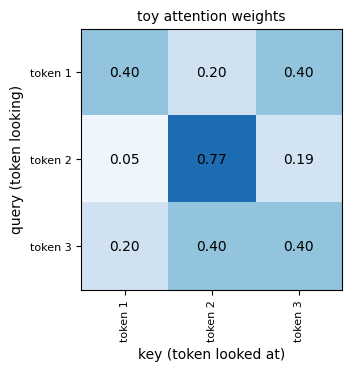

Toy example checks passed.


In [4]:
toy_tokens = ["token 1", "token 2", "token 3"]
toy_q = torch.tensor([[1.0, 0.0], [0.0, 2.0], [1.0, 1.0]])
toy_k = toy_q.clone()
toy_v = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])

toy_output, toy_weights = scaled_dot_product_attention(toy_q, toy_k, toy_v)
print("attention weights (one row per query):\n", toy_weights)
print("output (one row per token):\n", toy_output)


def plot_attention(axis, weights, tokens, title=""):
    # heatmap of a (T, T) attention matrix: row = the token that looks, column = the token looked at
    image = axis.imshow(weights, cmap="Blues", vmin=0, vmax=1)
    labels = [token.replace("▁", "") for token in tokens]  # sentencepiece marks the start of a word with "▁"
    axis.set_xticks(range(len(tokens)), labels=labels, rotation=90, fontsize=8)
    axis.set_yticks(range(len(tokens)), labels=labels, fontsize=8)
    axis.set_xlabel("key (token looked at)")
    axis.set_ylabel("query (token looking)")
    axis.set_title(title, fontsize=10)
    return image


fig, axis = plt.subplots(figsize=(3.6, 3.6), constrained_layout=True)
plot_attention(axis, toy_weights, toy_tokens, "toy attention weights")
for i in range(3):
    for j in range(3):
        axis.text(j, i, f"{toy_weights[i, j]:.2f}", ha="center", va="center", color="black")
plt.show()

assert toy_weights.shape == (3, 3) and toy_output.shape == (3, 2)
assert torch.allclose(toy_weights.sum(dim=-1), torch.ones(3))
assert torch.allclose(toy_weights[0], torch.tensor([0.4011, 0.1978, 0.4011]), atol=1e-4)
print("Toy example checks passed.")

PyTorch provides the same operation as `F.scaled_dot_product_attention` (it returns the output only). The next cell compares the two on random tensors with a batch dimension and a head dimension, with and without a mask.

In [5]:
torch.manual_seed(SEED)
q = torch.randn(2, 3, 5, 4)  # (B=2, heads=3, T=5, d_k=4)
k = torch.randn(2, 3, 5, 4)
v = torch.randn(2, 3, 5, 6)  # d_v = 6
random_mask = torch.rand(5, 5) > 0.4
random_mask.fill_diagonal_(True)  # every query may attend to at least one key

for name, mask in [("without mask", None), ("with a random mask", random_mask)]:
    our_output, our_weights = scaled_dot_product_attention(q, k, v, mask)
    torch_output = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)
    assert our_output.shape == (2, 3, 5, 6) and our_weights.shape == (2, 3, 5, 5)
    assert torch.allclose(our_output, torch_output, atol=1e-5)
    print(f"{name}: largest difference with PyTorch = {(our_output - torch_output).abs().max():.2e}")
print("Task 1 checks passed.")

without mask: largest difference with PyTorch = 1.19e-07
with a random mask: largest difference with PyTorch = 1.19e-07
Task 1 checks passed.


### 2.2 Why divide by $\sqrt{d_k}$?

If the entries of $q$ and $k$ are independent with mean 0 and variance 1, the score $q\cdot k=\sum_{m=1}^{d_k}q_mk_m$ is a sum of $d_k$ such products, so its variance is $d_k$: **the scores grow with the dimension**. Large scores make the softmax almost one-hot. Its gradient is then almost zero, and training becomes slow. Dividing by $\sqrt{d_k}$ brings the variance of the scores back to 1, whatever the dimension. The next cell checks this with one query and 10 keys.

In [6]:
torch.manual_seed(SEED)
print(f"{'d_k':>5} | {'std of the scores':>17} | {'std after / sqrt(d_k)':>21} | {'largest weight, no scaling':>26} | {'largest weight, scaled':>22}")
for d_k in (4, 64, 512):
    q = torch.randn(2000, 1, d_k)  # 2000 random queries
    k = torch.randn(2000, 10, d_k)  # 10 keys for each query
    raw_scores = q @ k.transpose(-2, -1)
    scaled_scores = raw_scores / math.sqrt(d_k)
    largest_raw = raw_scores.softmax(dim=-1).max(dim=-1).values.mean()
    largest_scaled = scaled_scores.softmax(dim=-1).max(dim=-1).values.mean()
    print(f"{d_k:>5} | {raw_scores.std():>17.2f} | {scaled_scores.std():>21.2f} | {largest_raw:>26.2f} | {largest_scaled:>22.2f}")

  d_k | std of the scores | std after / sqrt(d_k) | largest weight, no scaling | largest weight, scaled
    4 |              2.02 |                  1.01 |                       0.50 |                   0.31
   64 |              7.94 |                  0.99 |                       0.86 |                   0.32
  512 |             22.80 |                  1.01 |                       0.95 |                   0.32


### 2.3 The causal mask

Our language model predicts each token from the previous ones. During training, a whole sentence is processed in one pass. Without precaution, position $i$ could look at position $i+1$ and simply copy the word it must predict. The **causal mask** forbids this: token $i$ may attend to token $j$ only if $j\le i$. For $T=4$:

| | $j=0$ | $j=1$ | $j=2$ | $j=3$ |
|---|---|---|---|---|
| $i=0$ | True | False | False | False |
| $i=1$ | True | True | False | False |
| $i=2$ | True | True | True | False |
| $i=3$ | True | True | True | True |

The mask is `True` on and below the diagonal. Forbidden scores become $-\infty$, so they get a weight of exactly 0 after the softmax, and the remaining weights of each row still sum to 1.

---

**Task 2**: In the function `causal_mask` (next cell), complete the line `mask = ...`: a boolean tensor of shape `(size, size)` that is `True` on and below the diagonal. `torch.ones(size, size, dtype=torch.bool)` creates a matrix of `True`, and `torch.tril` keeps its lower triangle (diagonal included) and sets the rest to `False`.

In [7]:
def causal_mask(size, device=None):
    """
    input:
        size (int): sequence length T
        device: where to create the mask

    returns:
        mask (torch.Tensor): (T, T) booleans, mask[i, j] is True if j <= i
    """
    #mask = (torch.ones(size, size, dtype = torch.bool) if )
    mask = torch.tril(torch.ones(size, size, device=device)).bool() #> YOUR CODE HERE: True on and below the diagonal
    return mask


print(causal_mask(4))

tensor([[ True, False, False, False],
        [ True,  True, False, False],
        [ True,  True,  True, False],
        [ True,  True,  True,  True]])


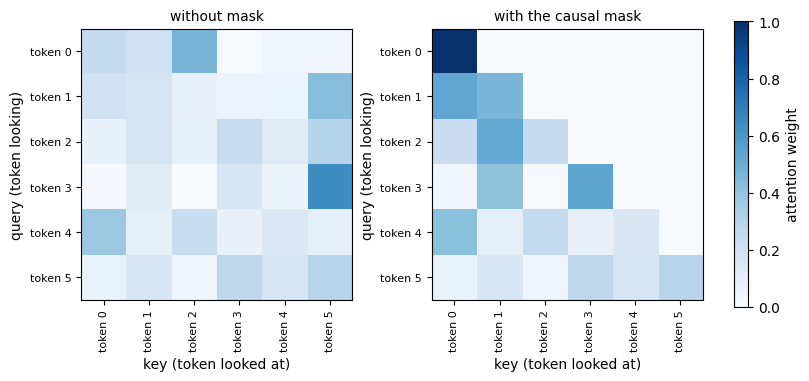

Task 2 checks passed.


In [8]:
torch.manual_seed(SEED)
T = 6
q, k, v = torch.randn(T, 4), torch.randn(T, 4), torch.randn(T, 4)
words = [f"token {i}" for i in range(T)]
_, weights_without_mask = scaled_dot_product_attention(q, k, v)
_, weights_with_mask = scaled_dot_product_attention(q, k, v, causal_mask(T))

fig, axes = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
plot_attention(axes[0], weights_without_mask, words, "without mask")
image = plot_attention(axes[1], weights_with_mask, words, "with the causal mask")
fig.colorbar(image, ax=axes, shrink=0.8, label="attention weight")
plt.show()

assert causal_mask(4).dtype == torch.bool
assert torch.equal(causal_mask(3), torch.tensor([[True, False, False], [True, True, False], [True, True, True]]))
assert torch.all(weights_with_mask.triu(diagonal=1) == 0), "a token attends to a later token"
assert torch.allclose(weights_with_mask.sum(dim=-1), torch.ones(T))
assert torch.allclose(weights_with_mask[0], torch.eye(T)[0]), "the first token can only attend to itself"
print("Task 2 checks passed.")


### 2.4 Multi-head self-attention

In a Transformer, the queries, keys and values are all computed from the same input $X$ (hence *self*-attention), by three learned linear maps:

$$
Q = XW_Q^\top + b_Q,\qquad K = XW_K^\top + b_K,\qquad V = XW_V^\top + b_V .
$$

With **multi-head** attention, the model runs $h$ attentions in parallel, each on its own slice of size $d_{\text{head}}=d_{\text{model}}/h$ of these vectors. Different heads can thus look for different things, for example the previous word or the subject of a verb. The outputs of the heads are concatenated and mixed by a last linear map, the output projection $W_O$.

For a batch of `B` sequences of `T` tokens:

| step | operation | shape |
|---|---|---|
| input | `x` | `(B, T, d_model)` |
| projections | `F.linear(x, self.in_proj_weight, self.in_proj_bias).chunk(3, dim=-1)` | three tensors `(B, T, d_model)` |
| split the heads | `.reshape(B, T, nhead, d_head).transpose(1, 2)` | `(B, nhead, T, d_head)` |
| attention in every head | `scaled_dot_product_attention` (Task 1) | output `(B, nhead, T, d_head)`, weights `(B, nhead, T, T)` |
| merge the heads | `.transpose(1, 2).reshape(B, T, d_model)` | `(B, T, d_model)` |
| output projection | `self.out_proj` | `(B, T, d_model)` |

Like PyTorch's `nn.MultiheadAttention`, we store $W_Q$, $W_K$ and $W_V$ stacked in one matrix `in_proj_weight` of shape `(3 * d_model, d_model)`, and the three biases in `in_proj_bias`. One call to `F.linear(x, weight, bias)`, which computes `x @ weight.T + bias`, gives the three projections at once, and `.chunk(3, dim=-1)` splits the result into `q`, `k` and `v`. Because our parameters have exactly the same names as PyTorch's, we can copy PyTorch's weights into our module. We will use this to check our code below, and later to load a pretrained model.

---

**Task 3**: In the method `forward` of `MultiHeadSelfAttention` (next cell), complete the seven lines, following the table above: the three projections `q, k, v = ...`; the split of the heads `q = ...`, `k = ...`, `v = ...`; the attention `output, weights = ...` with your function of Task 1; the merge of the heads `output = ...`; and the output projection `output = ...`. Keep `reshape` rather than `view` after a `transpose`.

In [9]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, nhead):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"
        self.nhead = nhead
        self.d_head = d_model // nhead
        # W_Q, W_K and W_V stacked in one matrix, with the same names as in nn.MultiheadAttention
        self.in_proj_weight = nn.Parameter(torch.empty(3 * d_model, d_model))
        self.in_proj_bias = nn.Parameter(torch.zeros(3 * d_model))
        self.out_proj = nn.Linear(d_model, d_model)
        nn.init.xavier_uniform_(self.in_proj_weight)
        nn.init.zeros_(self.out_proj.bias)

    def forward(self, x, mask=None):
        """
        input:
            x (torch.Tensor): (B, T, d_model)
            mask (torch.Tensor or None): (T, T) booleans, True where attention is allowed

        returns:
            output (torch.Tensor): (B, T, d_model)
            weights (torch.Tensor): (B, nhead, T, T) attention weights of every head
        """
        B, T, d_model = x.shape
        q, k, v = F.linear(x, self.in_proj_weight, self.in_proj_bias).chunk(3, dim = -1)  #> YOUR CODE HERE: the three projections, each of shape (B, T, d_model)
        q = q.reshape(B, T, self.nhead, self.d_head).transpose(1, 2)  #> YOUR CODE HERE: split the heads, (B, nhead, T, d_head)
        k = k.reshape(B, T, self.nhead, self.d_head).transpose(1, 2)  #> YOUR CODE HERE: same for the keys
        v = v.reshape(B, T, self.nhead, self.d_head).transpose(1, 2)  #> YOUR CODE HERE: same for the values
        output, weights = scaled_dot_product_attention(q,k,v, mask)  #> YOUR CODE HERE: attention in all the heads at once (Task 1)
        output = output.transpose(1,2).reshape(B,T,d_model)  #> YOUR CODE HERE: merge the heads, (B, T, d_model)
        output = self.out_proj(output)  #> YOUR CODE HERE: output projection
        return output, weights

The next cell creates PyTorch's `nn.MultiheadAttention` and our module with the same sizes, copies PyTorch's weights into ours with `load_state_dict`, and compares the outputs and the attention weights of every head.

Note that PyTorch's attention layers use the **opposite convention** for boolean masks: for them, `True` means *forbidden*. This is why we pass them `~mask`.

In [10]:
torch.manual_seed(SEED)
torch_mha = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
our_mha = MultiHeadSelfAttention(d_model=8, nhead=2)
print("parameters of nn.MultiheadAttention:")
for name, parameter in torch_mha.named_parameters():
    print(f"  {name:<18} {tuple(parameter.shape)}")
our_mha.load_state_dict(torch_mha.state_dict())  # copy PyTorch's weights into our module

x = torch.randn(3, 5, 8)  # 3 sequences of 5 tokens, d_model = 8
mask = causal_mask(5)
our_output, our_weights = our_mha(x, mask)
torch_output, torch_weights = torch_mha(x, x, x, attn_mask=~mask, need_weights=True, average_attn_weights=False)

print(f"\n{'tensor':<18} {'yours':<16} {'PyTorch':<16} {'expected':<16}")
print(f"{'output':<18} {str(tuple(our_output.shape)):<16} {str(tuple(torch_output.shape)):<16} {str((3, 5, 8)):<16}")
print(f"{'attention weights':<18} {str(tuple(our_weights.shape)):<16} {str(tuple(torch_weights.shape)):<16} {str((3, 2, 5, 5)):<16}")

assert our_output.shape == (3, 5, 8) and our_weights.shape == (3, 2, 5, 5)
assert torch.allclose(our_output, torch_output, atol=1e-5), "the outputs differ from nn.MultiheadAttention"
assert torch.allclose(our_weights, torch_weights, atol=1e-5), "the attention weights differ from nn.MultiheadAttention"
print("\nTask 3 checks passed: same outputs and same attention weights as nn.MultiheadAttention.")

parameters of nn.MultiheadAttention:
  in_proj_weight     (24, 8)
  in_proj_bias       (24,)
  out_proj.weight    (8, 8)
  out_proj.bias      (8,)

tensor             yours            PyTorch          expected        
output             (3, 5, 8)        (3, 5, 8)        (3, 5, 8)       
attention weights  (3, 2, 5, 5)     (3, 2, 5, 5)     (3, 2, 5, 5)    

Task 3 checks passed: same outputs and same attention weights as nn.MultiheadAttention.


## 3. The Transformer Block

### 3.1 Positional encoding

Attention on its own ignores the order of the tokens. If we shuffle the tokens of a sequence (without a mask), the outputs are shuffled in the same way and are otherwise unchanged, so "le chat mange la souris" and "la souris mange le chat" would get the same representations. The next cell checks this with our module.

In [11]:
torch.manual_seed(SEED)
x = torch.randn(1, 5, 8)
permutation = torch.tensor([3, 0, 4, 1, 2])
output, _ = our_mha(x)  # no mask
output_of_shuffled_input, _ = our_mha(x[:, permutation])
print("shuffling the input only shuffles the output:", torch.allclose(output[:, permutation], output_of_shuffled_input, atol=1e-6))

shuffling the input only shuffles the output: True


To give the model access to positions, we add to each token embedding a vector that depends on its position. Here we use the fixed sinusoidal encoding of the original Transformer:

$$
PE_{(pos,\,2i)}=\sin\left(\frac{pos}{10000^{2i/d}}\right),\qquad PE_{(pos,\,2i+1)}=\cos\left(\frac{pos}{10000^{2i/d}}\right).
$$

Each pair of dimensions oscillates at its own frequency, so every position gets a different code, and nearby positions get similar codes. The class `PositionalEncoding` below is provided. It stores the encodings in a tensor `pe` of shape `(max_len, 1, d)`, the layout used when the pretrained checkpoint of Section 8 was saved, and adds the first `T` rows to a batch of shape `(B, T, d)`.

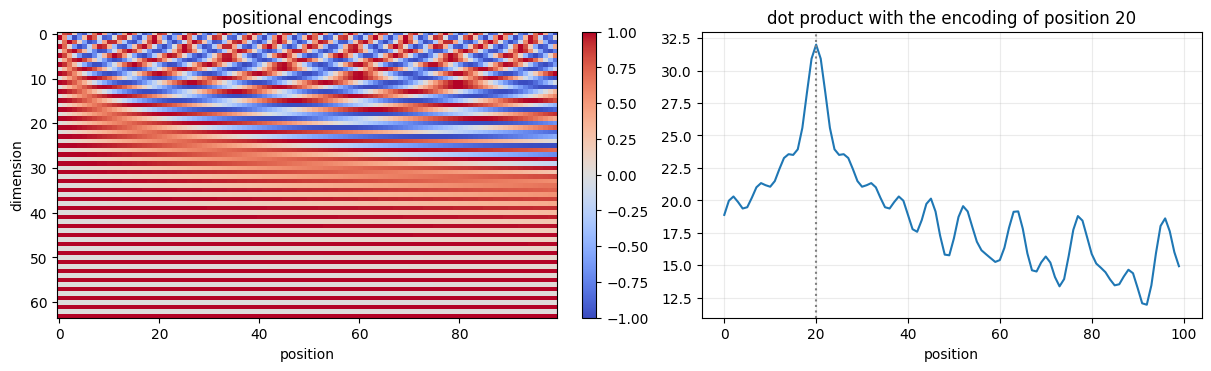

In [12]:
class PositionalEncoding(nn.Module):
    def __init__(self, nhid, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, nhid)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, nhid, 2).float() * (-math.log(10000.0) / nhid)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)  # (max_len, 1, nhid)
        self.register_buffer("pe", pe)

    def forward(self, x):
        # x: (B, T, nhid); self.pe[:T] has shape (T, 1, nhid), transposed to (1, T, nhid)
        x = x + self.pe[: x.size(1)].transpose(0, 1)
        return self.dropout(x)


positional_encoding = PositionalEncoding(nhid=64, dropout=0.0)
encodings = positional_encoding.pe[:100, 0]  # (100 positions, 64 dimensions)
assert torch.allclose(positional_encoding(torch.zeros(2, 7, 64))[1], encodings[:7])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
image = axes[0].imshow(encodings.T, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set(title="positional encodings", xlabel="position", ylabel="dimension")
fig.colorbar(image, ax=axes[0])
axes[1].plot(encodings @ encodings[20])
axes[1].axvline(20, color="0.5", linestyle=":")
axes[1].set(title="dot product with the encoding of position 20", xlabel="position")
axes[1].grid(alpha=0.25)
plt.show()

### 3.2 The Transformer block

A Transformer block combines multi-head self-attention with a small feed-forward network (FFN), each followed by a residual connection and a layer normalization. In the version of the original paper, which is also PyTorch's default `nn.TransformerEncoderLayer`:

$$
h=\operatorname{LayerNorm}_1\big(x+\operatorname{Dropout}_1(\operatorname{MHA}(x))\big),
\qquad
y=\operatorname{LayerNorm}_2\big(h+\operatorname{Dropout}_2(\operatorname{FFN}(h))\big),
$$

$$
\operatorname{FFN}(h)=\operatorname{Linear}_2\Big(\operatorname{Dropout}\big(\operatorname{ReLU}(\operatorname{Linear}_1(h))\big)\Big).
$$

- The attention mixes information **between** tokens. The FFN processes each token **separately**, with the same weights at every position.
- The **residual connections** ($x+\dots$) let information and gradients flow directly through many blocks.
- **LayerNorm** normalizes each token vector (mean 0 and variance 1, followed by a learned scale and shift), which stabilizes training.
- The shape does not change: `(B, T, d_model)` in and out, so blocks can be stacked.

Many recent models (GPT-2 and later) apply the LayerNorm *before* the attention and the FFN ("pre-norm", `norm_first=True` in PyTorch). We follow the original version here because the pretrained checkpoint used in this lab was trained with it.

---

**Task 4**: In the class `TransformerBlock` (next cell), complete the method `feed_forward` (one line, the FFN above) and the three lines of `forward`: the attention `attention_output, weights = ...` with your `MultiHeadSelfAttention`, then `h = ...` and `y = ...` following the two equations above. The layers are already created in `__init__`, with the same names as in `nn.TransformerEncoderLayer`.

In [13]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, nhead, dim_feedforward, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadSelfAttention(d_model, nhead)
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.linear2 = nn.Linear(dim_feedforward, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)  # inside the feed-forward network
        self.dropout1 = nn.Dropout(dropout)  # on the output of the attention
        self.dropout2 = nn.Dropout(dropout)  # on the output of the feed-forward network

    def feed_forward(self, h):
        return self.linear2(self.dropout(F.relu(self.linear1(h))))  #> YOUR CODE HERE: Linear_2(Dropout(ReLU(Linear_1(h))))

    def forward(self, x, mask=None):
        """
        input:
            x (torch.Tensor): (B, T, d_model)
            mask (torch.Tensor or None): (T, T) booleans, True where attention is allowed

        returns:
            y (torch.Tensor): (B, T, d_model)
            weights (torch.Tensor): (B, nhead, T, T) attention weights of every head
        """
        attention_output, weights = self.self_attn(x, mask)  #> YOUR CODE HERE: multi-head self-attention
        h = self.norm1(x + self.dropout1(attention_output)) #> YOUR CODE HERE: residual connection and LayerNorm_1
        y = self.norm2(h + self.dropout2(self.feed_forward(h)))  #> YOUR CODE HERE: feed-forward network, residual connection and LayerNorm_2
        return y, weights

As for the attention, we copy the weights of a PyTorch `nn.TransformerEncoderLayer` into our block and compare the outputs. Both are put in evaluation mode with `.eval()`, which switches dropout off: in training mode, dropout is random and the two outputs would differ.

In [14]:
def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


torch.manual_seed(SEED)
torch_layer = nn.TransformerEncoderLayer(d_model=8, nhead=2, dim_feedforward=16, dropout=0.1, batch_first=True)
our_block = TransformerBlock(d_model=8, nhead=2, dim_feedforward=16, dropout=0.1)
our_block.load_state_dict(torch_layer.state_dict())  # same parameter names, so the weights can be copied
torch_layer.eval()
our_block.eval()

x = torch.randn(3, 5, 8)
mask = causal_mask(5)
with torch.no_grad():
    our_output, our_weights = our_block(x, mask)
    torch_output = torch_layer(x, src_mask=~mask, is_causal=True)

print("output shape:", tuple(our_output.shape))
print(f"parameters: yours {count_parameters(our_block)}, PyTorch {count_parameters(torch_layer)}")
print(f"largest difference with PyTorch: {(our_output - torch_output).abs().max():.2e}")
assert our_output.shape == (3, 5, 8) and our_weights.shape == (3, 2, 5, 5)
assert count_parameters(our_block) == count_parameters(torch_layer)
assert torch.allclose(our_output, torch_output, atol=1e-5), "the output differs from nn.TransformerEncoderLayer"
print("Task 4 checks passed: same output as nn.TransformerEncoderLayer.")

output shape: (3, 5, 8)
parameters: yours 600, PyTorch 600
largest difference with PyTorch: 3.58e-07
Task 4 checks passed: same output as nn.TransformerEncoderLayer.


## 4. The Model

While the Transformer is a model that follows the encoder-decoder structure, it is possible to use only the encoder part (as in BERT) or the decoder part (as in GPT) to perform some specific tasks. In this notebook, we use a multi-layer Transformer decoder for the language model: a stack of the blocks of Section 3 with the causal mask. (In PyTorch, this block is called `nn.TransformerEncoderLayer`, because it has no cross-attention; with the causal mask, it behaves as a GPT-style decoder.)

The different layers used in this model are the following:

- The embedding layer
- Positional Embedding
- The transformer layers
- Linear layer for decoding and classification

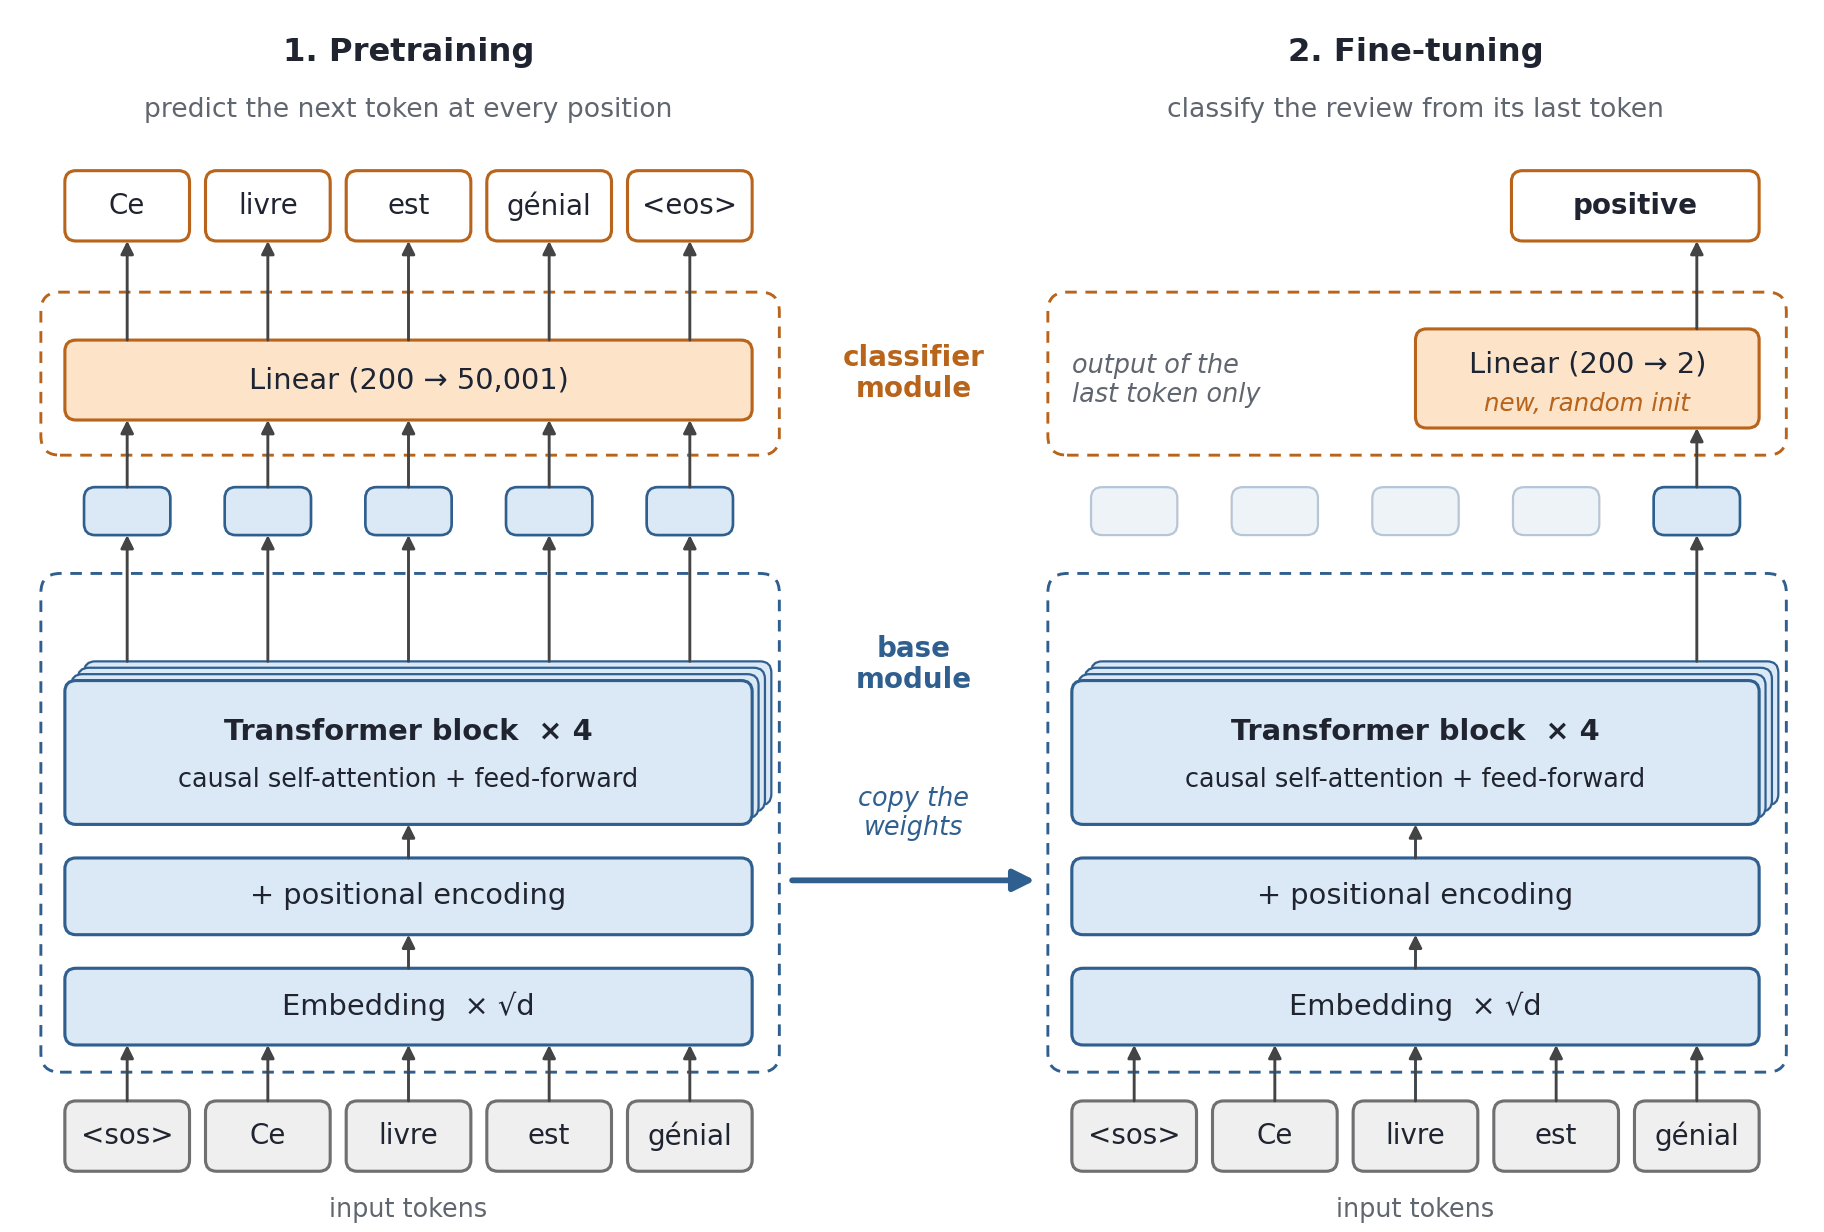

The same model can be used for language modeling and classification by just replacing the last layer in the model. This is why we split our model into two modules:

- base module: which consists of the 3 first layers.
- classifier module: which consists of the last layer.

After the pretraining, the parameters of the base model can be "transferred" to the model used in the classification task, while the classifier module should be replaced by a new head initialized randomly.

The base module can be built either with our own blocks (`implementation="ours"`) or with PyTorch's (`implementation="torch"`). Both have the same parameter names, so the same weights can be loaded into either of them. The class `TransformerStack` (provided) is our equivalent of `nn.TransformerEncoder`: a stack of `nlayers` blocks, which also returns the attention weights of every layer. PyTorch's version does not return them.

Some of the code is adapted from this nice tutorial: <a href="https://pytorch.org/tutorials/beginner/transformer_tutorial.html" target="_blank">https://pytorch.org/tutorials/beginner/transformer_tutorial.html</a>

---

**Task 5**: Fill in the gaps in the `TransformerModel`, `ClassificationHead` and `Model` classes (next cell) to implement the described model. All sequences are batch-first, of shape `(B, T)`.

In [15]:
class TransformerStack(nn.Module):
    # our equivalent of nn.TransformerEncoder: nlayers blocks applied one after the other
    def __init__(self, d_model, nhead, dim_feedforward, nlayers, dropout):
        super().__init__()
        self.layers = nn.ModuleList(
            [TransformerBlock(d_model, nhead, dim_feedforward, dropout) for _ in range(nlayers)]
        )

    def forward(self, x, mask):
        attention = []  # attention weights of every layer, each (B, nhead, T, T)
        for layer in self.layers:
            x, weights = layer(x, mask)
            attention.append(weights)
        return x, attention


class TransformerModel(nn.Module):
    def __init__(self, ntoken, nhead, nhid, nlayers, dropout=0.5, implementation="ours"):
        super(TransformerModel, self).__init__()
        '''
        ntoken: the size of vocabulary
        nhid: the hidden dimension of the model.
        We assume that embedding_dim = nhid = dim_feedforward
        nlayers: the number of Transformer blocks
        nhead: the number of heads in the multi-head attention
        dropout: the dropout value
        implementation: "ours" (our TransformerBlock) or "torch" (nn.TransformerEncoderLayer)
        '''
        self.model_type = "Transformer"
        self.implementation = implementation
        self.encoder = nn.Embedding(ntoken, nhid)  #> YOUR CODE HERE: the embedding layer, nhid = the dim_embed
        self.pos_encoder = PositionalEncoding(nhid)  #> YOUR CODE HERE: the positional encoding of Section 3.1
        if implementation == "torch":
            encoder_layers = nn.TransformerEncoderLayer(
                d_model=nhid,
                nhead=nhead,
                dim_feedforward=nhid,
                dropout=dropout,
                batch_first=True
            )  #> YOUR CODE HERE: one PyTorch block, d_model = dim_feedforward = nhid, batch_first=True
            self.transformer_encoder = nn.TransformerEncoder(
                encoder_layers,
                num_layers=nlayers,
                enable_nested_tensor=False
            )  #> YOUR CODE HERE: nlayers copies of this block, enable_nested_tensor=False
        else:
            self.transformer_encoder = TransformerStack(
                d_model=nhid,
                nhead=nhead,
                dim_feedforward=nhid,
                nlayers=nlayers,
                dropout=dropout
            )  #> YOUR CODE HERE: nlayers of our blocks, with dim_feedforward = nhid
        self.nhid = nhid
        self.init_weights()

    def init_weights(self):
        initrange = 0.1
        self.encoder.weight.data.uniform_(-initrange, initrange)

    def forward(self, src, return_attention=False):
        '''
        src: (B, T) token indices
        returns the output of the last block, (B, T, nhid), and, if return_attention is True,
        the list of the attention weights of every layer (None for implementation="torch")
        '''
        mask = causal_mask(src.size(1), device=src.device)
        x = self.encoder(src) * math.sqrt(self.nhid)
        x = self.pos_encoder(x)
        if self.implementation == "torch":
            output = self.transformer_encoder(x, mask=~mask)  #> YOUR CODE HERE: PyTorch's stack, with the mask in PyTorch's convention (~mask)
            attention = None  # nn.TransformerEncoder does not return the attention weights
        else:
            output, attention = self.transformer_encoder(x, mask)  #> YOUR CODE HERE: our stack
        if return_attention:
            return output, attention
        return output


class ClassificationHead(nn.Module):
    def __init__(self, nhid, nclasses):
        super(ClassificationHead, self).__init__()
        self.decoder = nn.Linear(nhid, nclasses)
        self.init_weights()

    def init_weights(self):
        initrange = 0.1
        self.decoder.bias.data.zero_()
        self.decoder.weight.data.uniform_(-initrange, initrange)

    def forward(self, src):
        output = self.decoder(src)  #> YOUR CODE HERE
        return output


class Model(nn.Module):
    def __init__(self, ntoken, nhead, nhid, nlayers, nclasses, dropout=0.5, implementation="ours"):
        super(Model, self).__init__()
        self.base = TransformerModel(ntoken, nhead, nhid, nlayers, dropout, implementation)
        self.classifier = ClassificationHead(nhid, nclasses)

    def forward(self, src, return_attention=False):
        # base model
        x, attention = self.base(src, return_attention=True)  #> YOUR CODE HERE: the base model, keeping the attention weights
        # classifier model
        output = self.classifier(x)  #> YOUR CODE HERE
        if return_attention:
            return output, attention
        return output

Let's verify if our model works, by applying one inference step. The cell also builds the same model with PyTorch's blocks, copies its weights into ours, and checks that both give the same output. The last check verifies the causal mask: changing a later token must not change the outputs at earlier positions.

In [16]:
ntokens = 100  # the size of vocabulary
nhid = 200  # hidden dimension
nlayers = 4  # the number of Transformer blocks
nhead = 2  # the number of heads in the multi-head attention
dropout = 0  # the dropout value

torch.manual_seed(SEED)
model = Model(ntokens, nhead, nhid, nlayers, ntokens, dropout).to(device)
torch_model = Model(ntokens, nhead, nhid, nlayers, ntokens, dropout, implementation="torch").to(device)

dummy_input = torch.tensor([[2, 6, 2, 5, 43, 21]]).to(device)  # one sequence of 6 tokens: shape (B=1, T=6)
out = model(dummy_input)
print(out.shape)  # is it the right shape?
assert out.shape == (1, 6, ntokens)

print(f"parameters: yours {count_parameters(model):,}, PyTorch {count_parameters(torch_model):,}")
assert set(model.state_dict()) == set(torch_model.state_dict()), "the parameter names differ from PyTorch's"
model.load_state_dict(torch_model.state_dict())
model.eval()
torch_model.eval()
with torch.no_grad():
    difference = (model(dummy_input) - torch_model(dummy_input)).abs().max().item()
    changed_input = dummy_input.clone()
    changed_input[0, -1] = 7  # change the last token only
    causal_difference = (model(changed_input)[:, :-1] - model(dummy_input)[:, :-1]).abs().max().item()
print(f"largest difference with PyTorch: {difference:.2e}")
assert difference < 1e-4
assert causal_difference < 1e-5, "a change of the last token modified earlier positions: check the causal mask"
print("Task 5 checks passed.")

torch.Size([1, 6, 100])
parameters: yours 1,008,100, PyTorch 1,008,100
largest difference with PyTorch: 4.77e-07
Task 5 checks passed.


## 5. Vocabulary and Tokenization

To train the language model, the text in our corpus should be first tokenized. We use sentencepiece <a href="https://github.com/google/sentencepiece">https://github.com/google/sentencepiece</a> that implements byte-pair-encoding (BPE), a sub-word tokenization algorithm.<br>
The vocabulary is given in `dict.txt` file. Let's load it, and map each token to a unique index.<br>

In our experiments we use datasets that are already tokenized.

---

**Task 6**: Fill in the gaps to create a `token2ind` and `ind2token` mapping dictionaries

In [17]:
path_vocab = DATA_DIR / "dict.txt"
with open(path_vocab, "r") as f:
    for _ in range(5):
        print(f.readline().rstrip())

▁d 1
es 1
▁l 1
en 1
on 1


In [18]:
token2ind = {"<sos>": 0, "<pad>": 1, "<eos>": 2, "<oov>": 3}  # the 4 first indices are reserved to special tokens
with open(path_vocab, "r") as f:
    for idx, line in enumerate(f):
        word = line.split()[0].strip()
        token2ind[word] = idx + 4 #> YOUR CODE HERE: the index of this word

ind2token = {index: token for token, index in token2ind.items()}  #> YOUR CODE HERE: the inverse mapping, from indices to tokens

print(ind2token[1111])
assert len(token2ind) == len(ind2token) == 50001
assert all(token2ind[ind2token[index]] == index for index in (0, 3, 4, 1111, 50000))

▁trop


## 6. Data Loader
We use the `DataLoader` class, to load our dataset and generate the mini-batches used in the training. `get_loader()` returns a `DataLoader` object, which is an iterable over data samples. The data loader can return mini-batches for language modeling or sequence classification based on the `task` argument that we pass to `get_loader()` function. Currently the function supports <i>language_modeling</i> and <i>classification</i> tasks.<br>

For the <i>language_modeling</i> task, both the input and the target are batches of sequences. In fact, the target is basically a shifted version of the input, in such a way that each token is predicted given all previous tokens. For example, for a sequence A B C D: <br>
<b>Input:</b> `<sos>` A B C D<br>
<b>Output:</b> A B C D `<eos>`<br>

For the <i>classification</i> task, the input is a batch of sequences and the target is a batch of scalar labels.<br>

The sequences of a mini-batch do not have the same length, so the shorter ones are padded **at the end** with the `<pad>` token. The batches are batch-first: the input has shape `(B, T)`.<br>
For more information about data loaders check: <a href="https://pytorch.org/docs/stable/data.html">https://pytorch.org/docs/stable/data.html</a>

---

**Task 7**: Fill in the gap inside `TextDataset` class in order to read the labels of the classification task: the file `path_labels` contains one integer label per line, in the same order as the documents.

In [19]:
class TextDataset(Dataset):
    def __init__(
        self,
        path_documents,
        path_labels=None,
        token2ind={},
        max_len=512,
        task="language_modeling",
    ):
        self.task = task
        self.max_len = max_len
        self.token2ind = token2ind
        self.documents = []
        self.labels = []
        with open(path_documents, "r") as f1:
            for line in f1:
                self.documents.append(line.strip())
        if task == "classification":
            # YOUR CODE HERE: read path_labels and append one integer label per line to self.labels
            with open(path_labels, 'r') as f2:
                for line in f2:
                    self.labels.append(int(line.strip()))
            assert len(self.labels) == len(self.documents)

    def __len__(self):
        return len(self.documents)

    def __getitem__(self, index):
        sequence = self.documents[index].split()
        if len(sequence) > self.max_len - 1:
            sequence = sequence[: self.max_len - 1]
        source_sequence = [self.token2ind["<sos>"]] + [
            self.token2ind[word] if word in self.token2ind else self.token2ind["<oov>"]
            for word in sequence
        ]
        if self.task == "language_modeling":
            target = source_sequence[1:]
            target.append(self.token2ind["<eos>"])
        elif self.task == "classification":
            target = [self.labels[index]]
        sample = {
            "source_sequence": torch.tensor(source_sequence),
            "target": torch.tensor(target),
        }
        return sample


def MyCollator(batch):
    source_sequences = pad_sequence(
        # we use padding to match the length of the sequences in the same batch
        [sample["source_sequence"] for sample in batch], batch_first=True, padding_value=token2ind["<pad>"]
    )
    target = pad_sequence(
        [sample["target"] for sample in batch], batch_first=True, padding_value=token2ind["<pad>"]
    )
    return source_sequences, target.reshape(-1)


def get_loader(
    path_documents,
    path_labels=None,
    token2ind={},
    max_len=512,
    batch_size=32,
    task="language_modeling",
    shuffle=True,
):
    dataset = TextDataset(
        path_documents,
        path_labels=path_labels,
        token2ind=token2ind,
        max_len=max_len,
        task=task,
    )
    data_loader = DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=MyCollator,
        pin_memory=False,
        drop_last=True,
    )
    return data_loader

In [20]:
path_data_train = DATA_DIR / "pretraining_subset.txt"

source, target = next(iter(get_loader(path_data_train, token2ind=token2ind, batch_size=4, shuffle=False)))
print("input shape:", tuple(source.shape), "  target shape:", tuple(target.shape))
print("input :", [ind2token[i] for i in source[0, :8].tolist()])
print("target:", [ind2token[i] for i in target.reshape(4, -1)[0, :8].tolist()])

input shape: (4, 44)   target shape: (176,)
input : ['<sos>', '▁Nicole', '-', 'Claude', '▁Mathieu', '▁est', '▁aussi', '▁très']
target: ['▁Nicole', '-', 'Claude', '▁Mathieu', '▁est', '▁aussi', '▁très', '▁critique']


## 7. The Training
In this section we will implement a `train()` function that trains our model for one epoch. As we said, in this lab we will use a language modeling objective in the pretraining phase. Given the previous tokens in a sequence, the model will try to predict the next one. The same function can be used for both pretraining and fine-tuning phase.<br>

The training procedure is as follows:<br>
1. Iterate over the data-loader.<br>
2. In each iteration perform one forward pass.<br>
3. Compute the gradients of the loss through back-propagation.<br>
4. Update the parameters of your model with the optimizer (here Adam).<br>
5. Repeat for <i>n</i> epochs<br>

<b>N.B:</b> While in the <i>language_modeling</i> task all the vectors at the output of the base model are used, in the <i>classification</i> task we only use the vector representing the last token to perform the prediction. Because of the causal mask, the last token is the only one that has seen the whole review. Since the shorter reviews of a batch are padded at the end, their last position is a `<pad>` token: the provided function `select_last_token` keeps, for each review, the output at its **last real token**.

---

**Task 8**: Fill in the gaps in `train()` function: the targets of the batch, the cross-entropy loss, and the accumulated loss used for logging.

In [21]:
def select_last_token(output, source):
    """
    Keeps, for each sequence of the batch, the output at its last real (non-<pad>) token
    input:
        output (torch.Tensor): (B, T, C) outputs at every position
        source (torch.Tensor): (B, T) token indices, padded with <pad> at the end

    returns:
        (torch.Tensor): (B, C)
    """
    lengths = (source != token2ind["<pad>"]).sum(dim=1)  # number of real tokens in each sequence
    return output[torch.arange(output.shape[0], device=output.device), lengths - 1]


def train(
    model,
    optimizer,
    criterion,
    path_data_train,
    path_labels_train=None,
    log_interval=5,
    task="language_modeling",
    batch_size=32,
    max_len=512,
    max_step: int = None,
    current_epoch=None,
):
    model.train()
    total_loss = 0.0
    steps_since_log = 0
    data_loader = get_loader(
        path_data_train,
        path_labels_train,
        token2ind,
        max_len=max_len,
        task=task,
        batch_size=batch_size,
    )

    losses = []
    for idx, data in enumerate(data_loader):  # 1
        optimizer.zero_grad()
        input = data[0].to(device)
        output = model(input)  # 2
        if task == "classification":
            output = select_last_token(output, input)
        output = output.reshape(-1, output.shape[-1])
        target = data[1]  #> YOUR CODE HERE: the targets of the batch
        target = target.to(device)
        loss = criterion(output, target)  #> YOUR CODE HERE: cross-entropy between the outputs and the targets
        loss.backward()  # 3
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.5)  # prevent exploding gradient
        optimizer.step()  # 4
        total_loss += loss.item()  #> YOUR CODE HERE: add the loss of this batch, as a Python number
        steps_since_log += 1
        if (idx % log_interval == 0 and idx > 0) or (max_step is not None and idx == max_step):
            cur_loss = total_loss / steps_since_log
            print(
                "| epoch {:3d} | {:5d}/{:5d} steps | "
                "loss {:5.5f} | ppl {:8.3f}".format(
                    current_epoch, idx, len(data_loader), cur_loss, math.exp(cur_loss),
                )
            )
            losses.append(cur_loss)
            total_loss = 0
            steps_since_log = 0

        if max_step is not None and idx >= max_step:
            break

    return losses

We now pretrain **our own implementation** on a tiny subset of French text, for a few steps only. A model that knows nothing predicts every token of the vocabulary with the same probability $1/50001$, so the loss starts around $\ln(50001)\approx10.8$.

In [22]:
ntokens = len(ind2token)  # the size of vocabulary
nhid = 200  # the dimension of the embeddings and of the feedforward network
nlayers = 4  # the number of Transformer blocks
nhead = 2  # the number of heads in the multi-head attention
dropout = 0  # the dropout value

nclasses = 2  # for classification task only

torch.manual_seed(SEED)
model = Model(ntokens, nhead, nhid, nlayers, ntokens, dropout).to(device)

# optimization parameters
criterion = nn.CrossEntropyLoss(ignore_index=token2ind["<pad>"])
lr = 0.0003  # learning rate
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

| epoch   1 |    25/ 3125 steps | loss 9.89315 | ppl 19794.344
| epoch   1 |    50/ 3125 steps | loss 8.51797 | ppl 5003.896
| epoch   1 |    75/ 3125 steps | loss 7.76597 | ppl 2358.940
| epoch   1 |   100/ 3125 steps | loss 7.55103 | ppl 1902.694
| epoch   1 |   125/ 3125 steps | loss 7.37574 | ppl 1596.777
| epoch   1 |   150/ 3125 steps | loss 7.35057 | ppl 1557.081
150 steps in 84 seconds


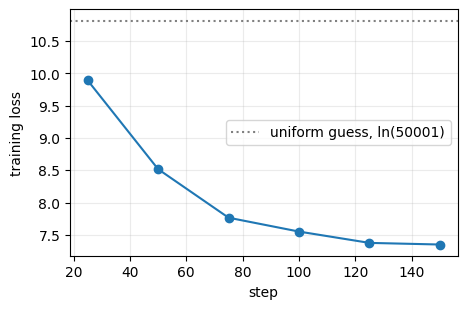

In [23]:
# pretraining on a tiny subset
log_interval = 25
max_step = 150
start = time.time()
pretraining_losses = train(
    model,
    optimizer,
    criterion,
    path_data_train,
    task="language_modeling",
    batch_size=16,
    log_interval=log_interval,
    max_step=max_step,
    current_epoch=1,
)
print(f"{max_step} steps in {time.time() - start:.0f} seconds")

plt.figure(figsize=(5, 3.2))
plt.plot(range(log_interval, max_step + 1, log_interval), pretraining_losses, marker="o")
plt.axhline(math.log(ntokens), color="0.5", linestyle=":", label="uniform guess, ln(50001)")
plt.xlabel("step")
plt.ylabel("training loss")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

## 8. Text Generation
Being trained on a language modeling objective, our model can be used in the inference mode to generate/complete sentences. However, the pretraining phase takes a lot of time compared to the fine-tuning.

Of course, we don't have enough time and resources to efficiently pretrain our model, so instead we will load the weights from a checkpoint that has been pre-trained for 12 hours on 1 GPU.<br>

Take a look here: <a href="https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-a-general-checkpoint-for-inference-and-or-resuming-training">https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-a-general-checkpoint-for-inference-and-or-resuming-training</a><br>

This checkpoint was trained with PyTorch's `nn.TransformerEncoder`. Since our implementation uses the same parameter names, we can load it into **both** implementations, and check that they compute the same thing.

In [24]:
checkpoint = torch.load(DATA_DIR / "pretrained_model_4layers.pt", map_location=device, weights_only=True)

pretrained_lm = Model(ntokens, nhead, nhid, nlayers, ntokens).to(device)  # our implementation
pretrained_lm.load_state_dict(checkpoint["model_state_dict"])
pretrained_lm.eval()

pretrained_lm_torch = Model(ntokens, nhead, nhid, nlayers, ntokens, implementation="torch").to(device)
pretrained_lm_torch.load_state_dict(checkpoint["model_state_dict"])
pretrained_lm_torch.eval()

Model(
  (base): TransformerModel(
    (encoder): Embedding(50001, 200)
    (pos_encoder): PositionalEncoding(
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer_encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-3): 4 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=200, out_features=200, bias=True)
          )
          (linear1): Linear(in_features=200, out_features=200, bias=True)
          (dropout): Dropout(p=0.5, inplace=False)
          (linear2): Linear(in_features=200, out_features=200, bias=True)
          (norm1): LayerNorm((200,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((200,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.5, inplace=False)
          (dropout2): Dropout(p=0.5, inplace=False)
        )
      )
    )
  )
  (classifier): ClassificationHead(
    (decoder): Linear(in_features=200, out_feat

In [25]:
s = spm.SentencePieceProcessor(model_file=str(DATA_DIR / "sentencepiece.french.model"))  # load sentencepiece model

# examples
encoded = s.encode_as_pieces("Bonjour les amis!")
decoded = s.decode_pieces(encoded)
print(encoded)
print(decoded)


def encode(sent):
    """sentence -> list of token indices, starting with <sos>"""
    pieces = s.encode_as_pieces(sent)
    return [token2ind["<sos>"]] + [token2ind.get(piece, token2ind["<oov>"]) for piece in pieces]


def decode(token_ids):
    """list of token indices -> sentence, without the special tokens"""
    return s.decode_pieces([ind2token[index] for index in token_ids if index >= 4])


source = torch.tensor([encode("Bonjour les amis!")], device=device)
with torch.no_grad():
    difference = (pretrained_lm(source) - pretrained_lm_torch(source)).abs().max().item()
print(f"\npretrained checkpoint, largest difference between our implementation and PyTorch's: {difference:.2e}")
assert difference < 1e-3

['▁Bonjour', '▁les', '▁amis', '!']
Bonjour les amis!

pretrained checkpoint, largest difference between our implementation and PyTorch's: 8.11e-06


---

**Task 9**: Implement the function `infer_next_tokens()` that takes as input a model, a string `sent` and an integer `max_len`, and returns a completion of the input sentence. Use greedy decoding: at each step, append the most probable next token given by `infer_next_token()`. The generation should stop when the model generates `<eos>` or when the sequence reaches `max_len` tokens.

In [26]:
@torch.no_grad()
def infer_next_token(model, token_ids):
    model.eval()
    source = torch.tensor([token_ids], device=next(model.parameters()).device)  # (1, T), on the device of the model
    out = model(source)  # (1, T, ntokens)
    next_token_ind = out[0, -1].argmax(-1).item()  # most probable token after the last position
    return next_token_ind


def infer_next_tokens(model, sent, max_len=50):
    token_ids = encode(sent)
    while len(token_ids) < max_len:  # greedy
        # YOUR CODE HERE: get the next token with infer_next_token; stop if it is <eos>, otherwise append it to token_ids
        next_token_ind = infer_next_token(model, token_ids)
        if next_token_ind == token2ind["<eos>"]:
            break

        token_ids.append(next_token_ind)
    return decode(token_ids)

In [27]:
sent = "Bonjour les"
print(infer_next_tokens(pretrained_lm, sent))

for sent in ["Bonjour les", "Ce livre est", "Le président de la République"]:
    ours, theirs = infer_next_tokens(pretrained_lm, sent), infer_next_tokens(pretrained_lm_torch, sent)
    assert ours == theirs, "the two implementations generate different texts"
print("Task 9 checks passed: both implementations generate the same texts.")

Bonjour les gens qui ont été très accueillants et sympathiques.
Task 9 checks passed: both implementations generate the same texts.


## 9. Visualizing Attention

Our implementation has one advantage over `nn.TransformerEncoder`: it returns the attention weights. The pretrained model has 4 layers of 2 heads, so it computes 8 attention maps for every sentence. Let's look at them.

---

**Task 10**: Complete the two lines of `collect_attention` (next cell): run the model on the sentence with `return_attention=True` to get the list of the attention weights of every layer (one tensor of shape `(1, nhead, T, T)` per layer), then stack this list into a single tensor of shape `(nlayers, nhead, T, T)`, without the batch dimension. `torch.stack` turns a list of tensors into one tensor with a new first dimension.

attention: (4, 2, 14, 14)   tokens: ['<sos>', '▁Le', '▁chat', '▁de', '▁ma', '▁voisine', '▁dort', '▁toute', '▁la', '▁journée', '▁sur', '▁le', '▁canapé', '▁.']


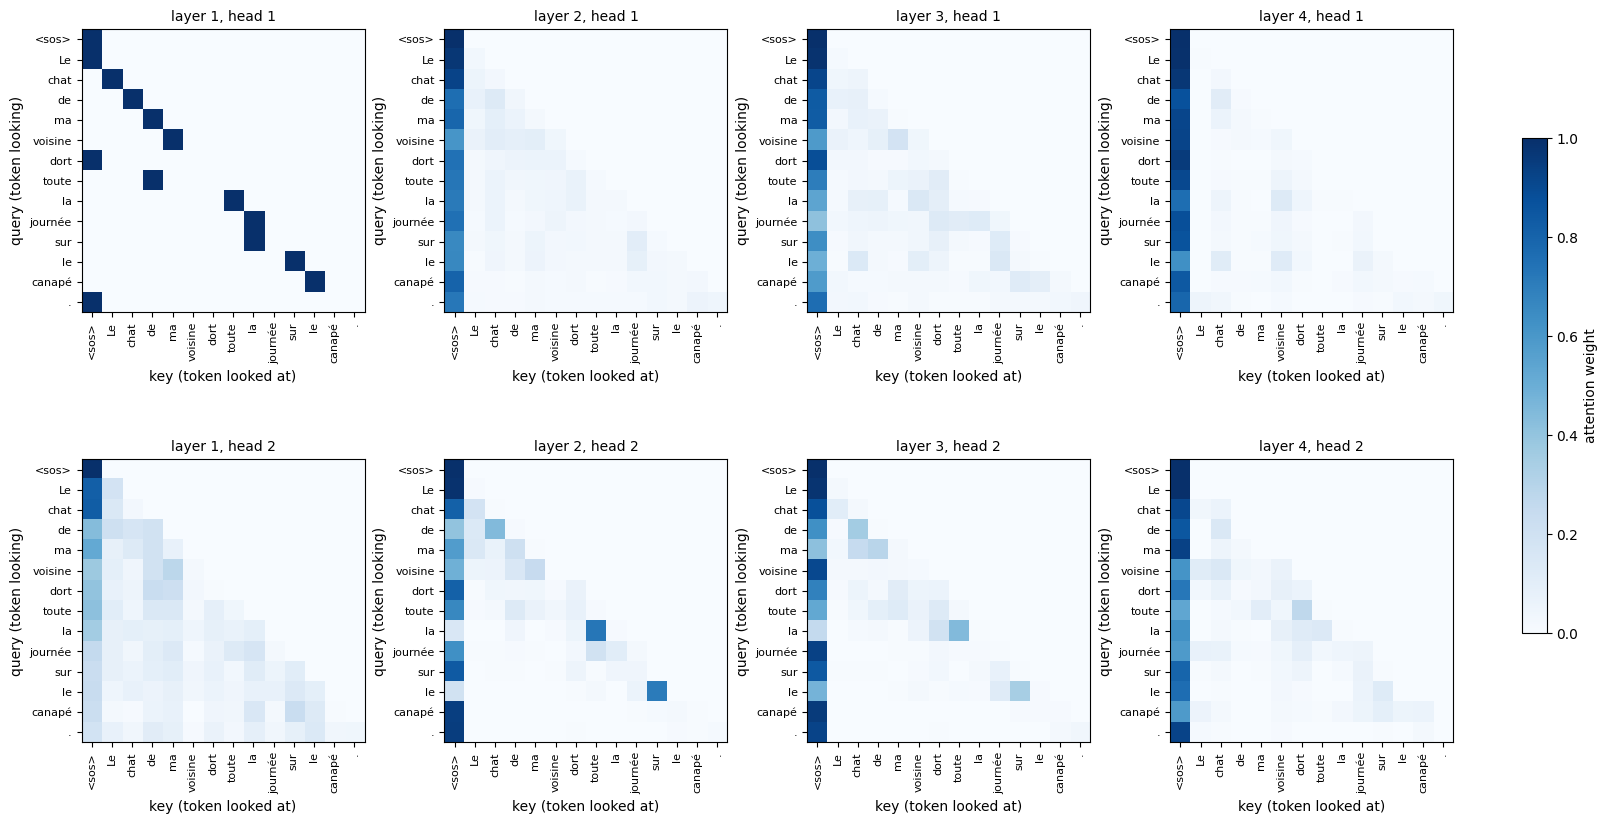

In [28]:
@torch.no_grad()
def collect_attention(model, sent):
    """
    returns:
        attention (torch.Tensor): (nlayers, nhead, T, T) attention weights of the sentence, on the CPU
        tokens (list of str): the T tokens of the sentence, starting with <sos>
    """
    model.eval()
    token_ids = encode(sent)
    source = torch.tensor([token_ids], device=device)
    _, attention = model(source, return_attention=True)  #> YOUR CODE HERE: run the model and keep the list of attention weights
    attention = torch.stack(attention).squeeze(1).cpu()  #> YOUR CODE HERE: stack the layers and remove the batch dimension
    tokens = [ind2token[index] for index in token_ids]
    return attention, tokens


sentence = "Le chat de ma voisine dort toute la journée sur le canapé ."
attention, tokens = collect_attention(pretrained_lm, sentence)
print("attention:", tuple(attention.shape), "  tokens:", tokens)
assert attention.shape == (nlayers, nhead, len(tokens), len(tokens))
assert torch.allclose(attention.sum(dim=-1), torch.ones(nlayers, nhead, len(tokens)), atol=1e-4)

fig, axes = plt.subplots(nhead, nlayers, figsize=(16, 8.6), constrained_layout=True)
for layer in range(nlayers):
    for head in range(nhead):
        image = plot_attention(axes[head, layer], attention[layer, head], tokens, f"layer {layer + 1}, head {head + 1}")
fig.colorbar(image, ax=axes, shrink=0.6, label="attention weight")
plt.show()

To compare the heads with numbers rather than by eye, the next cell measures, for every head and averaged over a few sentences, how much attention a token gives on average to the **previous token**, to **itself**, and to the first token **`<sos>`**. The first two rows of each map are left out: the first token can only look at itself, and for the second token, the previous token is `<sos>`.

In [29]:
def head_statistics(attention):
    # attention: (nlayers, nhead, T, T) -> three (nlayers, nhead) tensors
    T = attention.shape[-1]
    rows = torch.arange(2, T)  # leave out the first two tokens
    previous = attention[:, :, rows, rows - 1].mean(dim=-1)
    itself = attention[:, :, rows, rows].mean(dim=-1)
    first = attention[:, :, rows, 0].mean(dim=-1)
    return previous, itself, first


sentences = [
    "Le chat de ma voisine dort toute la journée sur le canapé .",
    "Ce roman raconte la vie d une famille pendant la guerre .",
    "Les enfants jouent dans le jardin pendant que leurs parents préparent le repas .",
    "Il faut absolument lire ce livre au moins une fois dans sa vie .",
    "La fin du film est un peu triste mais les acteurs sont excellents .",
]
statistics = [head_statistics(collect_attention(pretrained_lm, sent)[0]) for sent in sentences]
previous, itself, first = [torch.stack(values).mean(dim=0) for values in zip(*statistics)]

print(f"{'layer':>5} {'head':>5} | {'previous token':>14} | {'itself':>7} | {'<sos>':>6}")
for layer in range(nlayers):
    for head in range(nhead):
        print(f"{layer + 1:>5} {head + 1:>5} | {previous[layer, head]:>14.2f} | {itself[layer, head]:>7.2f} | {first[layer, head]:>6.2f}")

layer  head | previous token |  itself |  <sos>
    1     1 |           0.64 |    0.00 |   0.31
    1     2 |           0.13 |    0.06 |   0.35
    2     1 |           0.05 |    0.03 |   0.75
    2     2 |           0.24 |    0.02 |   0.62
    3     1 |           0.09 |    0.03 |   0.68
    3     2 |           0.12 |    0.02 |   0.74
    4     1 |           0.02 |    0.02 |   0.84
    4     2 |           0.08 |    0.03 |   0.72


**Questions**:

1. Why is the upper-right triangle of every map empty?
2. Find a head that mostly looks at the previous token. Why can such a head be useful to predict the next word?
3. Several heads put a large part of their attention on `<sos>`, which carries no information about the sentence. Since the weights of each row must sum to 1, what can a head do when there is nothing useful to look at?
4. Can we conclude from these maps alone how the model chooses the next word?

Answers:

1. The upper-right triangle of each map is empty because we use the masked self-attention, to predict the next word, the model must not have access to the words on its right side. 
2. Layer one, Head 1 looks at the previous token the most, with value of 0.64. This is useful for the next word's prediction because tokens next to each other tend to have similar grammatical and semantic relationships. 
3. When there is nothing useful to look at, it can just put its attention score on <sos> which acts as an attention sink since the sum has to be one and we cannot assign zero to everything.
4. We cannot conclude on these attention map alone. They only show us how 'attention' is distributed between tokens in the same sentence/sequence. The final result depends on other factors such as the value vectors, feed-forward networks, Add and Norm layer, etc.

## 10. Supervised Task
It's time to train the model on the supervised task, which is in our case sentiment analysis. It consists of predicting whether a book review is a positive or a negative review. The model will be trained in 2 settings.<br>
<ul>
    <li>Training from scratch: All model parameters are randomly initialized.</li>
    <li>Transfer learning: Only the classification head is trained from scratch, all other parameters are copied from the pre-trained model.</li>
</ul>

The training function is already implemented. However, to evaluate the model at each epoch we have to implement a function that computes the accuracy of the model on the validation set. To save time, the reviews are cut after 256 tokens (about 89% of the reviews are shorter).

In [30]:
path_data_train = DATA_DIR / "train.review.spm"
path_labels_train = DATA_DIR / "train.label"

path_data_valid = DATA_DIR / "test.review.spm"
path_labels_valid = DATA_DIR / "test.label"

max_len_reviews = 256

---

**Task 11:** Implement the <code>evaluate_accuracy()</code> function. This function takes as input a model and a <code>data_loader</code> and returns a float: the fraction of correctly classified reviews.<br>

In [31]:
# a function to evaluate the validation accuracy of the model.
def evaluate_accuracy(model, data_loader):
    model.eval()
    ncorrect = ntotal = 0
    with torch.no_grad():
        for idx, data in enumerate(data_loader):
            input = data[0].to(device)
            # inference
            output = model(input)  #> YOUR CODE HERE: the outputs of the model at every position
            output = select_last_token(output, input)  # only the vector of the last token
            # total number of examples
            ntotal += input.size(0)  #> YOUR CODE HERE: the number of reviews in this batch
            # number of correct predictions
            predictions = torch.argmax(output, -1)
            ncorrect += (predictions == data[1].to(device)).sum().item()  #> YOUR CODE HERE: the number of correct predictions in this batch
    acc = ncorrect / ntotal
    return acc

In [32]:
# save the base model to be loaded later in the fine-tuning phase
torch.save({"model_state_dict": pretrained_lm.base.state_dict()}, DATA_DIR / "pretrained_model_4layers_no_class_head.pt")

valid_loader = get_loader(
    path_data_valid,
    path_labels_valid,
    token2ind=token2ind,
    max_len=max_len_reviews,
    batch_size=20,
    task="classification",
    shuffle=False,
)

**Before running the next cell:** which setting do you expect to reach a good accuracy faster, and which one do you expect to reach the best accuracy? Give one reason for each.

In [33]:
from_scratch_settings = [True, False]

from_scratch_valid_acc = []
pretrained_valid_acc = []
finetuned_models = {}
lr = 0.0001
epochs = 6

for from_scratch in from_scratch_settings:
    torch.manual_seed(SEED)
    model = Model(ntokens, nhead, nhid, nlayers, 2, dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if not from_scratch:
        print("=====PRETRAINED MODEL======")
        # load checkpoint
        checkpoint = torch.load(DATA_DIR / "pretrained_model_4layers_no_class_head.pt", map_location=device, weights_only=True)
        # load state dict
        model.base.load_state_dict(checkpoint["model_state_dict"])
    else:
        print("=====TRAINING FROM SCRATCH======")
    start = time.time()
    for epoch in range(1, epochs + 1):
        train(
            model,
            optimizer,
            criterion,
            path_data_train,
            path_labels_train,
            task="classification",
            batch_size=8,
            max_len=max_len_reviews,
            log_interval=50,
            current_epoch=epoch,
        )
        acc = evaluate_accuracy(model, valid_loader)
        print("validation accuracy: {:.4f}".format(acc))
        if from_scratch:
            from_scratch_valid_acc.append(acc)
        else:
            pretrained_valid_acc.append(acc)
    finetuned_models["from scratch" if from_scratch else "pretrained"] = model
    print(f"training time: {time.time() - start:.0f} seconds")
    print()

=====TRAINING FROM SCRATCH======
| epoch   1 |    50/  200 steps | loss 0.81157 | ppl    2.251
| epoch   1 |   100/  200 steps | loss 0.71396 | ppl    2.042
| epoch   1 |   150/  200 steps | loss 0.67819 | ppl    1.970
validation accuracy: 0.6150
| epoch   2 |    50/  200 steps | loss 0.61863 | ppl    1.856
| epoch   2 |   100/  200 steps | loss 0.60359 | ppl    1.829
| epoch   2 |   150/  200 steps | loss 0.61257 | ppl    1.845
validation accuracy: 0.6515
| epoch   3 |    50/  200 steps | loss 0.48536 | ppl    1.625
| epoch   3 |   100/  200 steps | loss 0.46806 | ppl    1.597
| epoch   3 |   150/  200 steps | loss 0.35156 | ppl    1.421
validation accuracy: 0.6915
| epoch   4 |    50/  200 steps | loss 0.20633 | ppl    1.229
| epoch   4 |   100/  200 steps | loss 0.19745 | ppl    1.218
| epoch   4 |   150/  200 steps | loss 0.28383 | ppl    1.328
validation accuracy: 0.7460
| epoch   5 |    50/  200 steps | loss 0.08527 | ppl    1.089
| epoch   5 |   100/  200 steps | loss 0.08569 | 

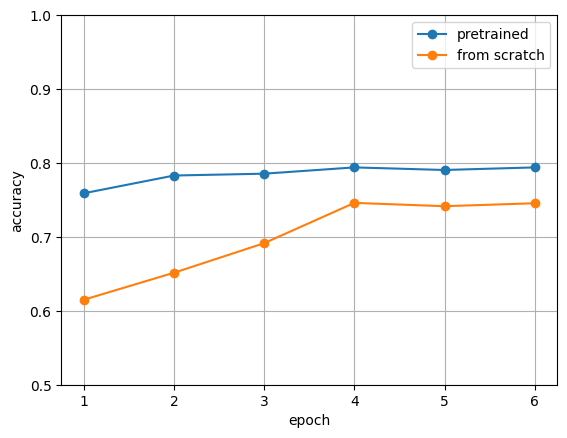

In [34]:
plt.grid()
plt.plot(range(1, epochs + 1), pretrained_valid_acc, marker="o", label="pretrained")
plt.plot(range(1, epochs + 1), from_scratch_valid_acc, marker="o", label="from scratch")
plt.ylim(0.5, 1.0)
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

Which words does the classifier use? The next cell takes two short validation reviews, one negative and one positive, that both models classify correctly. For each fine-tuned model, it shows the attention of the **last token** (the one used for the prediction) in the **last layer**, averaged over the two heads. The darker the background, the larger the attention. The weight on `<sos>` is not shown, and the colours are rescaled for each model, so compare **where** the attention goes rather than how dark the colours are. You can change the condition in the cell to look at reviews that a model gets wrong.

In [35]:
@torch.no_grad()
def last_token_attention(model, token_ids):
    model.eval()
    source = torch.tensor([token_ids], device=device)
    logits, attention = model(source, return_attention=True)
    weights = attention[-1][0, :, -1].mean(dim=0).cpu()  # last layer, last token, mean over the heads: (T,)
    probability_positive = logits[0, -1].softmax(dim=-1)[1].item()
    return weights, probability_positive


def highlight(tokens, weights):
    spans = []
    for token, weight in zip(tokens, weights):
        text = escape(token.replace("▁", " "))
        spans.append(f'<span style="background-color: rgba(255, 140, 0, {weight:.2f}); padding: 1px 0;">{text}</span>')
    return "".join(spans)


validation_reviews = [line.split() for line in open(path_data_valid)]
validation_labels = [int(line) for line in open(path_labels_valid)]


def review_token_ids(review):
    return [token2ind["<sos>"]] + [token2ind.get(piece, token2ind["<oov>"]) for piece in review]


def correctly_classified(index):
    # True if every fine-tuned model predicts the right label for this review
    label = validation_labels[index]
    return all(
        (last_token_attention(finetuned, review_token_ids(validation_reviews[index]))[1] > 0.5) == (label == 1)
        for finetuned in finetuned_models.values()
    )


# the first short negative review and the first short positive review that both models classify correctly
chosen = [
    next(
        index for index, review in enumerate(validation_reviews)
        if 20 <= len(review) <= 45 and validation_labels[index] == label and correctly_classified(index)
    )
    for label in (0, 1)
]

html = ""
for index in chosen:
    review = validation_reviews[index]
    html += f"<p><b>review {index}, true label: {'positive' if validation_labels[index] == 1 else 'negative'}</b></p>"
    for name, finetuned in finetuned_models.items():
        weights, probability_positive = last_token_attention(finetuned, review_token_ids(review))
        weights = weights[1:] / weights[1:].max()  # leave out <sos>, rescale to [0, 1]
        html += f"<p><i>{name}</i> (probability of a positive review: {probability_positive:.2f})<br>{highlight(review, weights)}</p>"
    html += "<hr>"
display(HTML(html))

# Wrap-Up

- Attention computes, for every token, a weighted average of the values of the tokens it may look at. The weights are a softmax of query-key scores, divided by $\sqrt{d_k}$ to keep them in a reasonable range.
- The causal mask lets a language model be trained on whole sentences at once, while each position only sees the previous tokens.
- Multi-head attention runs several attentions in parallel on slices of the representation. A Transformer block adds a feed-forward network, residual connections and layer normalization; blocks keep the shape and can be stacked.
- With the same weights, our implementation and PyTorch's compute the same function. PyTorch's is faster; ours lets us inspect the attention weights.
- Attention maps show where each head takes information from. They are a useful hint, not an explanation of the prediction.
- Pretraining on raw text (self-supervised learning) gives representations that transfer: the pretrained model fine-tunes faster and better than a model trained from scratch on the same labelled data.

# 11. Bonus (Optional): Faster Generation with a KV Cache

`infer_next_tokens` recomputes the whole sequence at every step: to generate token $t+1$, the model processes the $t$ previous tokens again. This is wasteful. Because of the causal mask, the representation of a token in every layer only depends on the tokens before it, so it **does not change** when new tokens are appended. In particular, the keys and values of the previous tokens are the same at every step.

Language models used in practice, such as ChatGPT or Llama, therefore store the keys and values of the previous tokens of every layer in a **KV cache**. At each step, only the newest token goes through the model: its query attends to the cached keys and values, and its own key and value are added to the cache. We implement this with our own attention, and measure the speed-up.

In this bonus, the cache of one layer is a dictionary `{"k": keys, "v": values}` with two tensors of shape `(1, nhead, t, d_head)` for the `t` tokens already processed, or `None` before the first token.

---

**Bonus task 1**: In the function `attention_step` (next cell), complete the three lines: append the key and the value of the new token at the end of the cached ones (`torch.cat` along the token dimension, `dim=2`), then compute the attention of the new query over all the keys with your function of Task 1. No mask is needed: the newest token may attend to every previous token and to itself.

In [36]:
def attention_step(attention_layer, x_new, cache):
    """
    Multi-head self-attention for the newest token only
    input:
        attention_layer (MultiHeadSelfAttention): the layer whose weights we use
        x_new (torch.Tensor): (1, 1, d_model) input of the newest token
        cache (dict or None): {"k": (1, nhead, t, d_head), "v": (1, nhead, t, d_head)} for the t previous tokens

    returns:
        output (torch.Tensor): (1, 1, d_model)
        cache (dict): keys and values of the t + 1 tokens
    """
    B, T, d_model = x_new.shape
    nhead, d_head = attention_layer.nhead, attention_layer.d_head
    q, k, v = F.linear(x_new, attention_layer.in_proj_weight, attention_layer.in_proj_bias).chunk(3, dim=-1)
    q = q.reshape(B, T, nhead, d_head).transpose(1, 2)  # (1, nhead, 1, d_head)
    k = k.reshape(B, T, nhead, d_head).transpose(1, 2)
    v = v.reshape(B, T, nhead, d_head).transpose(1, 2)
    if cache is not None:
        k = torch.cat([cache["k"], k], dim=2)  #> YOUR CODE HERE: the cached keys followed by the new key, (1, nhead, t + 1, d_head)
        v = torch.cat([cache["v"], v], dim=2)  #> YOUR CODE HERE: same for the values
    output, _ = scaled_dot_product_attention(q, k, v)  #> YOUR CODE HERE: the new query attends to all the keys
    output = attention_layer.out_proj(output.transpose(1, 2).reshape(B, T, d_model))
    return output, {"k": k, "v": v}


@torch.no_grad()
def model_step(model, token_id, position, caches):
    """
    Runs the newest token through the whole model, using and updating the caches of every layer
    returns the scores of the next token, (ntokens,)
    """
    base = model.base
    x = base.encoder(torch.tensor([[token_id]], device=base.encoder.weight.device)) * math.sqrt(base.nhid)
    x = x + base.pos_encoder.pe[position]  # positional encoding of this position
    for i, block in enumerate(base.transformer_encoder.layers):
        attention_output, caches[i] = attention_step(block.self_attn, x, caches[i])
        h = block.norm1(x + attention_output)
        x = block.norm2(h + block.feed_forward(h))
    return model.classifier(x)[0, -1]

---

**Bonus task 2**: In the function `infer_next_tokens_with_cache` (next cell), write the greedy generation loop. The provided lines already read the prompt one token at a time, which fills the caches, and leave in `scores` the scores of the token that follows the prompt. Each new token then needs a **single** call to `model_step`: choose the most probable token, stop if it is `<eos>` (only when `stop_at_eos` is `True`), otherwise append it to `token_ids` and run it through `model_step` at its position, `len(token_ids) - 1`.

In [37]:
@torch.no_grad()
def infer_next_tokens_with_cache(model, sent, max_len=50, stop_at_eos=True):
    model.eval()
    token_ids = encode(sent)
    caches = [None] * len(model.base.transformer_encoder.layers)  # one cache per layer
    for position, token_id in enumerate(token_ids):  # read the prompt, which fills the caches
        scores = model_step(model, token_id, position, caches)
    # YOUR CODE HERE: greedy generation, one call to model_step per new token
    while len(token_ids) < max_len:
        next_token_id = scores.argmax(-1).item()
        if stop_at_eos and next_token_id == token2ind["<eos>"]:
            break

        token_ids.append(next_token_id)
        scores = model_step(
            model,
            next_token_id,
            len(token_ids) - 1,
            caches
        )
    return decode(token_ids)


for sent in ["Bonjour les", "Ce livre est", "Le président de la République"]:
    with_cache = infer_next_tokens_with_cache(pretrained_lm, sent)
    print(with_cache)
    assert with_cache == infer_next_tokens(pretrained_lm, sent), "the cache changes the generated text"
print("Bonus checks passed: the KV cache generates the same texts.")

Bonjour les gens qui ont été très accueillants et sympathiques.
Ce livre est un peu plus facile à comprendre.
Le président de la République a été élu au suffrage universel direct, mais il a été élu au suffrage universel direct.
Bonus checks passed: the KV cache generates the same texts.


Now we time the two methods. To compare them on the same number of tokens, we ignore `<eos>` and generate a fixed number of new tokens. We run this comparison on a copy of the model on the **CPU**: when a small model processes a single token at a time, a GPU spends most of its time on the fixed cost of launching each operation, which hides the difference between the two methods.

  50 new tokens: without cache 0.36 s, with KV cache 0.11 s, same text: True
 100 new tokens: without cache 0.83 s, with KV cache 0.20 s, same text: True
 200 new tokens: without cache 2.44 s, with KV cache 0.40 s, same text: True
 400 new tokens: without cache 8.48 s, with KV cache 0.84 s, same text: True


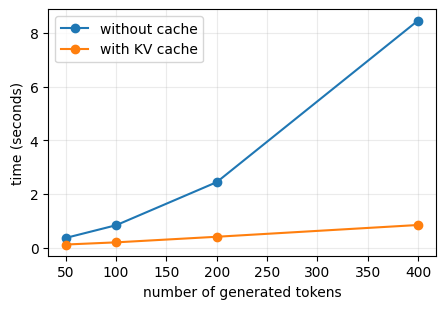

In [38]:
@torch.no_grad()
def generate_without_cache(model, sent, n_tokens):
    token_ids = encode(sent)
    for _ in range(n_tokens):
        token_ids.append(infer_next_token(model, token_ids))
    return decode(token_ids)


cpu_lm = Model(ntokens, nhead, nhid, nlayers, ntokens)  # a copy of the pretrained model, on the CPU
cpu_lm.load_state_dict(pretrained_lm.state_dict())
cpu_lm.eval()

prompt = "Ce livre est"
lengths = [50, 100, 200, 400]
times = {"without cache": [], "with KV cache": []}
for n_tokens in lengths:
    start = time.time()
    text_without = generate_without_cache(cpu_lm, prompt, n_tokens)
    times["without cache"].append(time.time() - start)
    start = time.time()
    text_with = infer_next_tokens_with_cache(cpu_lm, prompt, max_len=len(encode(prompt)) + n_tokens, stop_at_eos=False)
    times["with KV cache"].append(time.time() - start)
    print(f"{n_tokens:>4} new tokens: without cache {times['without cache'][-1]:.2f} s, with KV cache {times['with KV cache'][-1]:.2f} s, same text: {text_without == text_with}")

plt.figure(figsize=(5, 3.2))
for name, values in times.items():
    plt.plot(lengths, values, marker="o", label=name)
plt.xlabel("number of generated tokens")
plt.ylabel("time (seconds)")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

**Questions**:

1. Without a cache, how many token positions does the model process in total to generate $n$ tokens after a prompt of $p$ tokens? And with the cache? How does the time grow with $n$ in each case?
2. The cache stores, for every token and every layer, one key and one value of size `d_model`. How many numbers does it store per token for our model (4 layers, `d_model` = 200)? For a large model with 32 layers and `d_model` = 4096, in 16-bit floats (2 bytes per number), how much memory does the cache take for a context of 4,096 tokens?

Answers:
1. Without the cache, the number of token position proceeded is $p+(p+1)+(p+2)+\cdots+(p+n-1) = \sum_{i=0}^{n-1}(p+i) = np + \frac{n(n − 1)}{2}$ because as mention above, for generation token t+1, the model process the entire t token again. 
With cache, we proceed the p at once then for each token generated, we count just one operation, thus the total is $p + n -1$. The time grows quadratically with n, $O(n^2)$.

2. For our model, it stores $2\times4\times200 $ = $1600$ per token. 
For a larger model with 32 layers, the cache takes, for a context of 4096 tokens, $2\times32\times4096 \times 2 $ bytes $\times 4096$ tokens $= 2147483648$ bytes of memory. 


